In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)

DATA_PATH = "../data/raw/paysim.parquet"
FIGURES_PATH = Path("../reports/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        FIGURES_PATH / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

df = pd.read_parquet(DATA_PATH)
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [2]:
df.shape

(6362620, 11)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,6362620.0,2.433972e+02,1.423320e+02,1.0,156.00,239.000,3.350000e+02,7.430000e+02
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.57,74871.940,2.087215e+05,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.00,14208.000,1.073152e+05,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.00,0.000,1.442584e+05,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.00,132705.665,9.430367e+05,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.00,214661.440,1.111909e+06,3.561793e+08
isFraud,6362620.0,1.290820e-03,3.590480e-02,0.0,0.00,0.000,0.000000e+00,1.000000e+00
isFlaggedFraud,6362620.0,2.514687e-06,1.585775e-03,0.0,0.00,0.000,0.000000e+00,1.000000e+00


In [5]:
summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Non-Null Count": df.notna().sum(),
    "Missing Values": df.isna().sum(),
    "Missing (%)": df.isna().mean() * 100,
    "Unique Values": df.nunique()
})

summary

,Data Type,Non-Null Count,Missing Values,Missing (%),Unique Values
step,int64,6362620,0,0.0,743
type,str,6362620,0,0.0,5
amount,float64,6362620,0,0.0,5316900
nameOrig,str,6362620,0,0.0,6353307
oldbalanceOrg,float64,6362620,0,0.0,1845844
newbalanceOrig,float64,6362620,0,0.0,2682586
nameDest,str,6362620,0,0.0,2722362
oldbalanceDest,float64,6362620,0,0.0,3614697
newbalanceDest,float64,6362620,0,0.0,3555499
isFraud,int64,6362620,0,0.0,2


Feature	Description

step	Simulation time in hours

type	Transaction type

amount	Transaction amount

nameOrig	Sender account identifier

oldbalanceOrg	Sender balance before transaction

newbalanceOrig	Sender balance after transaction
nameDest	Recipient account identifier

oldbalanceDest	Recipient balance before transaction

newbalanceDest	Recipient balance after transaction

isFraud	Fraud classification target

isFlaggedFraud	Existing rule-based fraud flag

In [6]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
numeric_cols = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

pd.DataFrame({
    "Negative Values": (df[numeric_cols] < 0).sum(),
    "Zero Values": (df[numeric_cols] == 0).sum(),
    "Zero (%)": (df[numeric_cols] == 0).mean() * 100
})

,Negative Values,Zero Values,Zero (%)
amount,0,16,0.000251
oldbalanceOrg,0,2102449,33.043762
newbalanceOrig,0,3609566,56.730812
oldbalanceDest,0,2704388,42.504314
newbalanceDest,0,2439433,38.340071


In [9]:
fraud_distribution = pd.DataFrame({
    "Count": df["isFraud"].value_counts(),
    "Percentage": df["isFraud"].value_counts(normalize=True) * 100
})

fraud_distribution.index = ["Legitimate", "Fraudulent"]
fraud_distribution

,Count,Percentage
Legitimate,6354407,99.870918
Fraudulent,8213,0.129082


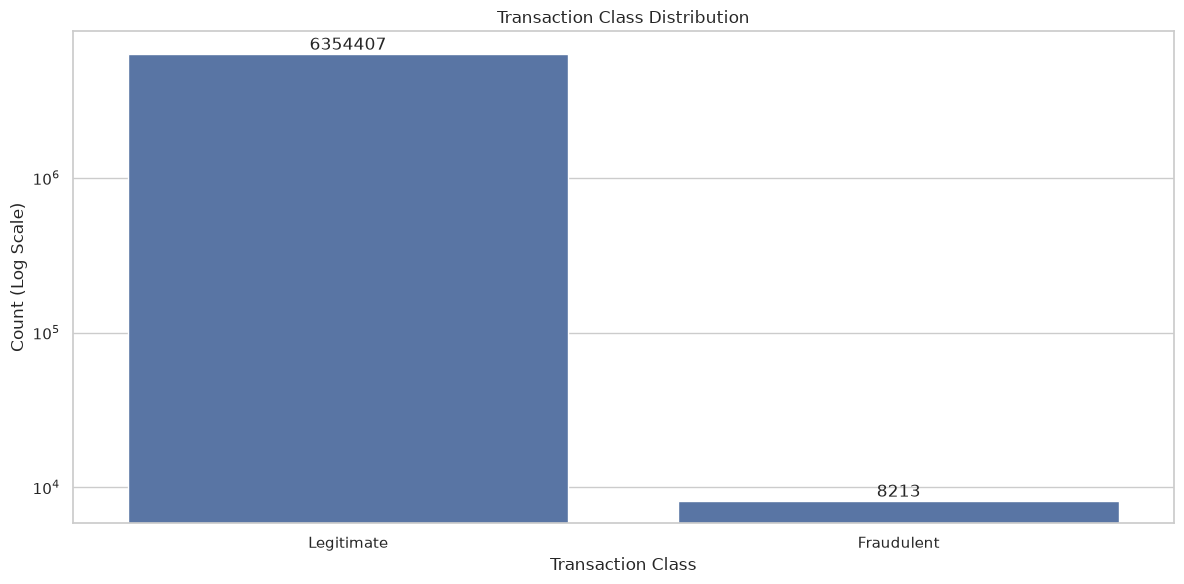

In [10]:
ax = sns.countplot(data=df, x="isFraud")

ax.bar_label(ax.containers[0], fmt="%d")

plt.yscale("log")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])
plt.title("Transaction Class Distribution")
plt.xlabel("Transaction Class")
plt.ylabel("Count (Log Scale)")
save_plot("eda_class_distribution.png")

In [11]:
df["type"].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

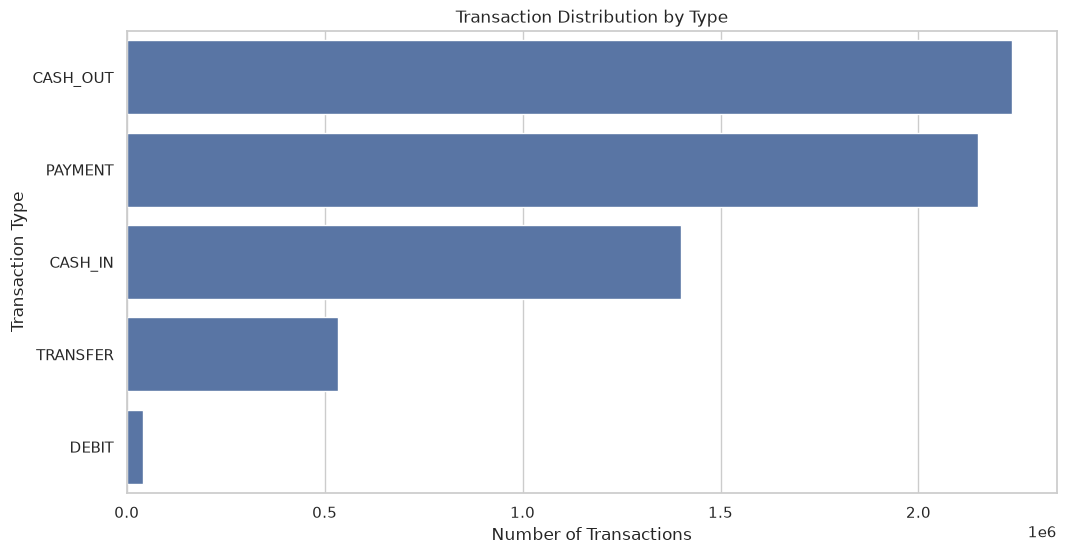

In [12]:
sns.countplot(
    data=df,
    y="type",
    order=df["type"].value_counts().index
)

plt.title("Transaction Distribution by Type")
plt.xlabel("Number of Transactions")
plt.ylabel("Transaction Type")
plt.show()

In [13]:
type_summary = df.groupby("type").agg(
    total_transactions=("isFraud", "count"),
    fraudulent_transactions=("isFraud", "sum"),
    average_amount=("amount", "mean"),
    total_amount=("amount", "sum")
)

type_summary["fraud_rate"] = (
    type_summary["fraudulent_transactions"] /
    type_summary["total_transactions"] * 100
)

type_summary.sort_values("fraud_rate", ascending=False)

,total_transactions,fraudulent_transactions,average_amount,total_amount,fraud_rate
type,,,,,
TRANSFER,532909,4097,910647.009645,4.852920e+11,0.768799
CASH_OUT,2237500,4116,176273.964346,3.944130e+11,0.183955
CASH_IN,1399284,0,168920.242004,2.363674e+11,0.000000
DEBIT,41432,0,5483.665314,2.271992e+08,0.000000
PAYMENT,2151495,0,13057.604660,2.809337e+10,0.000000


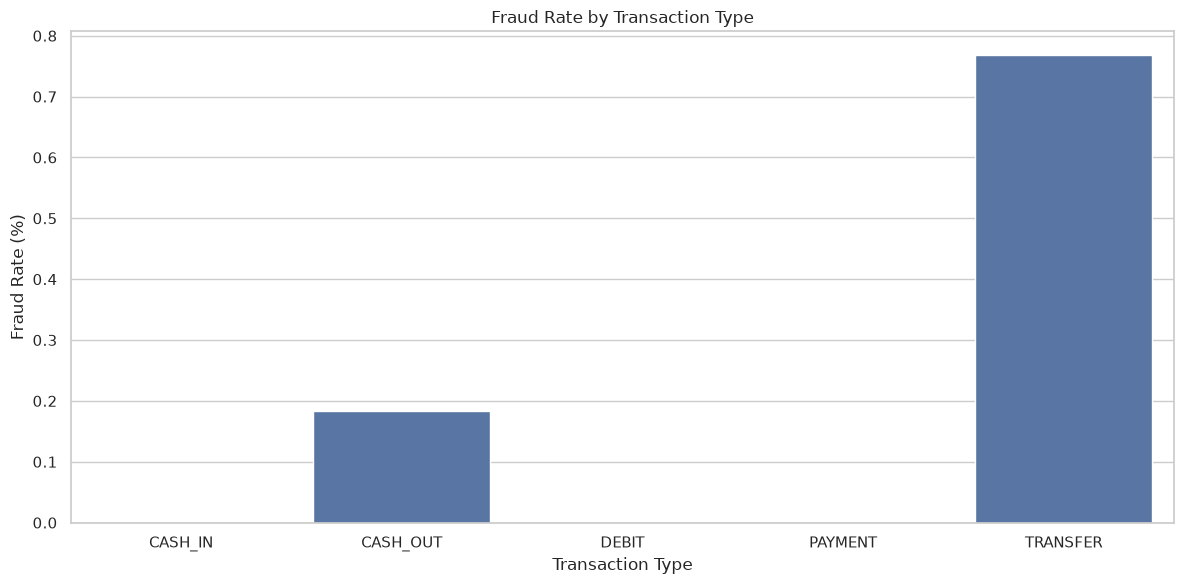

In [14]:
sns.barplot(
    data=type_summary.reset_index(),
    x="type",
    y="fraud_rate"
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
save_plot("eda_fraud_rate_by_type.png")

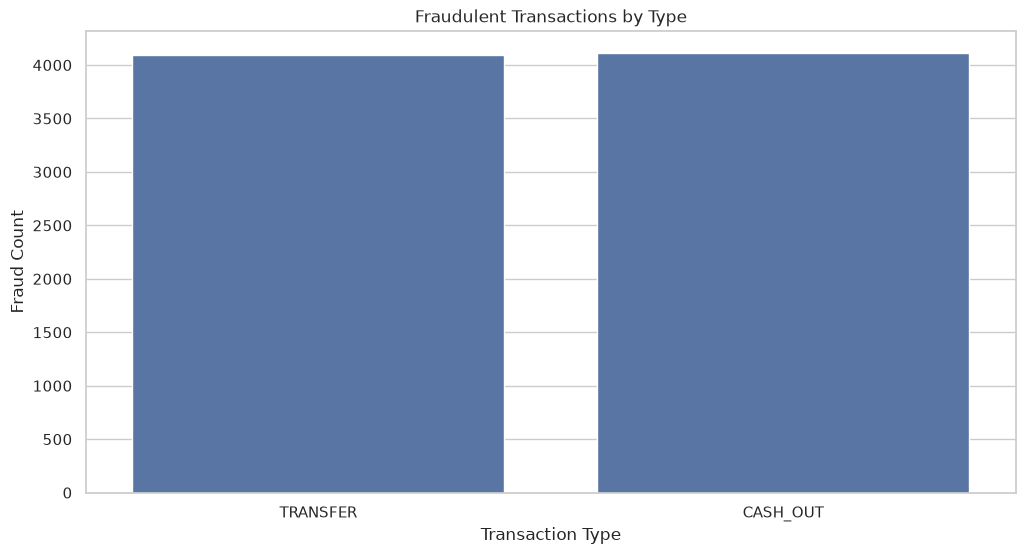

In [15]:
sns.countplot(
    data=df[df["isFraud"] == 1],
    x="type"
)

plt.title("Fraudulent Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Count")
plt.show()

In [16]:
df.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


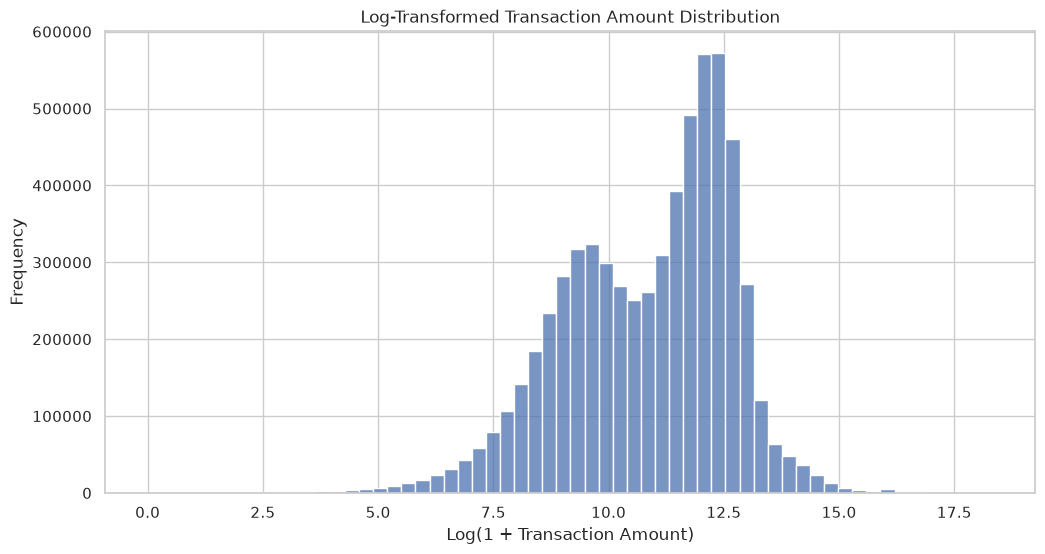

In [17]:
sns.histplot(
    x=np.log1p(df["amount"]),
    bins=60
)

plt.title("Log-Transformed Transaction Amount Distribution")
plt.xlabel("Log(1 + Transaction Amount)")
plt.ylabel("Frequency")
plt.show()

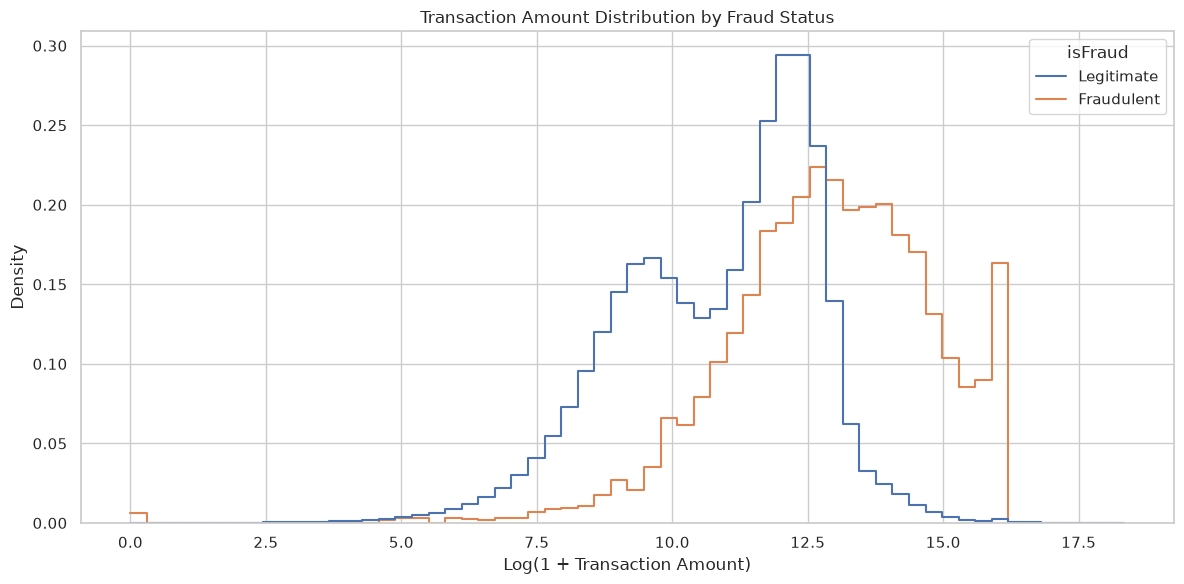

In [18]:
sns.histplot(
    x=np.log1p(df["amount"]),
    hue=df["isFraud"].map({0: "Legitimate", 1: "Fraudulent"}),
    bins=60,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Transaction Amount Distribution by Fraud Status")
plt.xlabel("Log(1 + Transaction Amount)")
plt.ylabel("Density")
save_plot("eda_amount_by_fraud_status.png")

In [19]:
amount_summary = df.groupby("isFraud").agg(
    total_amount=("amount", "sum"),
    mean_amount=("amount", "mean"),
    median_amount=("amount", "median"),
    max_amount=("amount", "max")
)

amount_summary

,total_amount,mean_amount,median_amount,max_amount
isFraud,,,,
0,1.132337e+12,1.781970e+05,74684.72,92445516.64
1,1.205642e+10,1.467967e+06,441423.44,10000000.00


In [20]:
fraud_amount = df.loc[df["isFraud"] == 1, "amount"].sum()
total_amount = df["amount"].sum()

print(f"Total Transaction Amount: {total_amount:,.2f}")
print(f"Total Fraudulent Transaction Amount: {fraud_amount:,.2f}")
print(f"Fraudulent Amount Percentage: {fraud_amount / total_amount:.4%}")

Total Transaction Amount: 1,144,392,944,759.77
Total Fraudulent Transaction Amount: 12,056,415,427.84
Fraudulent Amount Percentage: 1.0535%


In [21]:
df["step"].describe()

count    6.362620e+06
mean     2.433972e+02
std      1.423320e+02
min      1.000000e+00
25%      1.560000e+02
50%      2.390000e+02
75%      3.350000e+02
max      7.430000e+02
Name: step, dtype: float64

In [22]:
hourly_summary = df.groupby("step").agg(
    total_transactions=("isFraud", "count"),
    fraudulent_transactions=("isFraud", "sum"),
    total_amount=("amount", "sum")
)

hourly_summary["fraud_rate"] = (
    hourly_summary["fraudulent_transactions"] /
    hourly_summary["total_transactions"] * 100
)

hourly_summary.head()

,total_transactions,fraudulent_transactions,total_amount,fraud_rate
step,,,,
1,2708,16,2.854292e+08,0.590842
2,1014,8,8.592160e+07,0.788955
3,552,4,4.329388e+07,0.724638
4,565,10,7.291003e+07,1.769912
5,665,6,4.554809e+07,0.902256


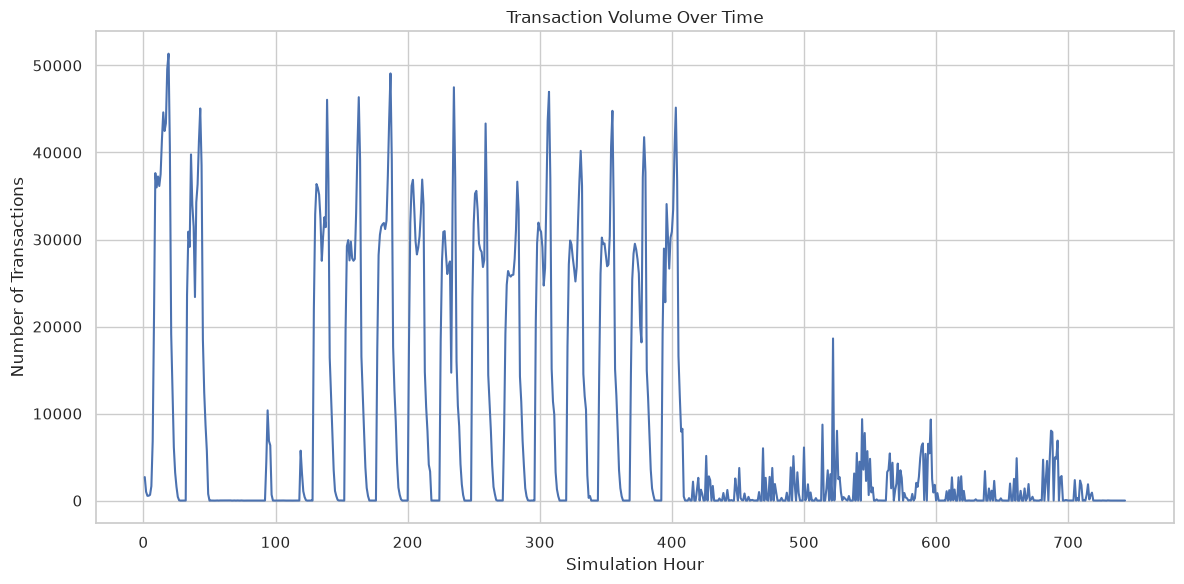

In [23]:
plt.plot(
    hourly_summary.index,
    hourly_summary["total_transactions"]
)

plt.title("Transaction Volume Over Time")
plt.xlabel("Simulation Hour")
plt.ylabel("Number of Transactions")
save_plot("eda_transaction_volume_over_time.png")

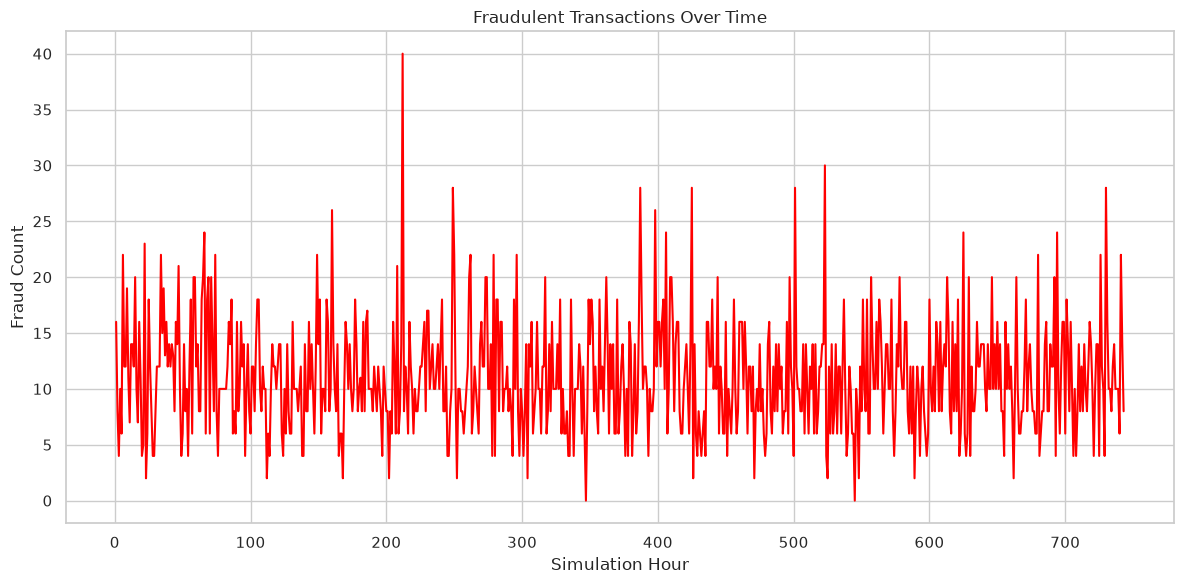

In [24]:
plt.plot(
    hourly_summary.index,
    hourly_summary["fraudulent_transactions"],
    color="red"
)

plt.title("Fraudulent Transactions Over Time")
plt.xlabel("Simulation Hour")
plt.ylabel("Fraud Count")
save_plot("eda_fraud_count_over_time.png")

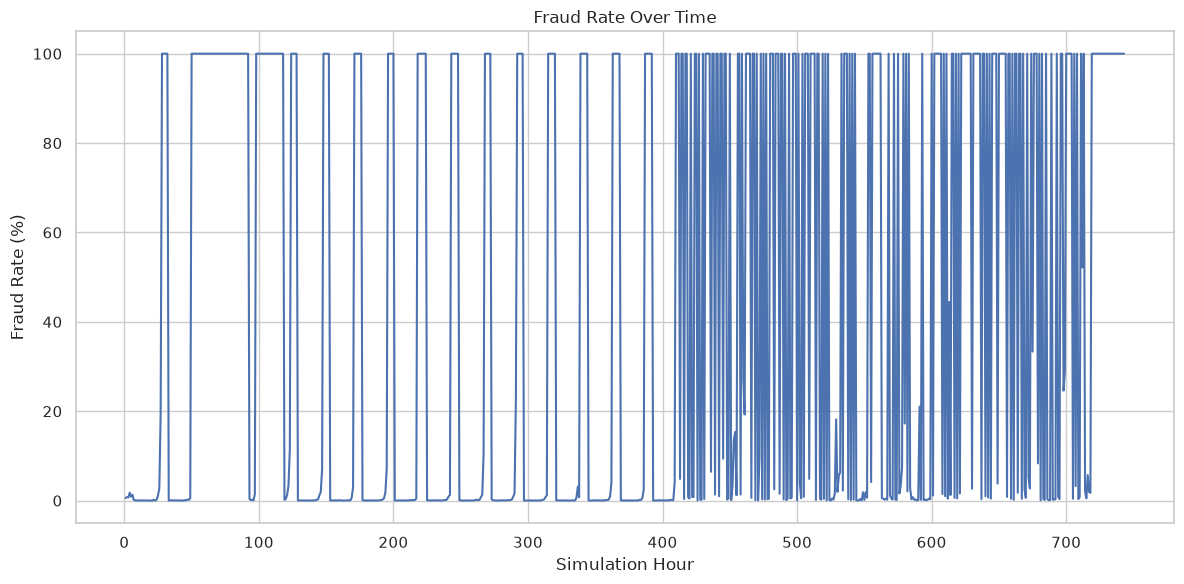

In [25]:
plt.plot(
    hourly_summary.index,
    hourly_summary["fraud_rate"]
)

plt.title("Fraud Rate Over Time")
plt.xlabel("Simulation Hour")
plt.ylabel("Fraud Rate (%)")
save_plot("eda_fraud_rate_over_time.png")

In [26]:
print("Unique Sender Accounts:", df["nameOrig"].nunique())
print("Unique Recipient Accounts:", df["nameDest"].nunique())

Unique Sender Accounts: 6353307
Unique Recipient Accounts: 2722362


In [27]:
sender_activity = df.groupby("nameOrig").agg(
    transaction_count=("amount", "count"),
    total_amount=("amount", "sum"),
    fraud_count=("isFraud", "sum")
)

sender_activity.describe()

,transaction_count,total_amount,fraud_count
count,6.353307e+06,6.353307e+06,6.353307e+06
mean,1.001466e+00,1.801256e+05,1.292713e-03
std,3.832002e-02,6.043381e+05,3.593107e-02
min,1.000000e+00,0.000000e+00,0.000000e+00
25%,1.000000e+00,1.341488e+04,0.000000e+00
50%,1.000000e+00,7.506847e+04,0.000000e+00
75%,1.000000e+00,2.089948e+05,0.000000e+00
max,3.000000e+00,9.244552e+07,1.000000e+00


In [28]:
recipient_activity = df.groupby("nameDest").agg(
    transaction_count=("amount", "count"),
    total_amount=("amount", "sum"),
    fraud_count=("isFraud", "sum")
)

recipient_activity.describe()

,transaction_count,total_amount,fraud_count
count,2.722362e+06,2.722362e+06,2.722362e+06
mean,2.337169e+00,4.203677e+05,3.016866e-03
std,4.549264e+00,2.061382e+06,5.513701e-02
min,1.000000e+00,0.000000e+00,0.000000e+00
25%,1.000000e+00,5.588630e+03,0.000000e+00
50%,1.000000e+00,1.299293e+04,0.000000e+00
75%,1.000000e+00,3.549397e+04,0.000000e+00
max,1.130000e+02,3.574408e+08,2.000000e+00


In [29]:
recipient_activity.sort_values(
    "transaction_count", ascending=False
).head(10)

,transaction_count,total_amount,fraud_count
nameDest,,,
C1286084959,113,7.742894e+07,0
C985934102,109,4.242289e+07,0
C665576141,105,8.874938e+07,0
C2083562754,102,5.307394e+07,0
C248609774,101,4.068016e+07,0
C1590550415,101,4.320610e+07,0
C1789550256,99,1.778853e+08,0
C451111351,99,3.745303e+07,0
C1360767589,98,3.512129e+07,0


In [30]:
account_summary = df.groupby(
    df["nameDest"].str[0]
).agg(
    total_transactions=("isFraud", "count"),
    fraudulent_transactions=("isFraud", "sum")
)

account_summary["fraud_rate"] = (
    account_summary["fraudulent_transactions"] /
    account_summary["total_transactions"] * 100
)

account_summary

,total_transactions,fraudulent_transactions,fraud_rate
nameDest,,,
C,4211125,8213,0.195031
M,2151495,0,0.000000


In [31]:
balance_cols = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

df.groupby("isFraud")[balance_cols].median()

,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,14069.00,0.0,133311.8,214881.70
1,438983.45,0.0,0.0,4676.42


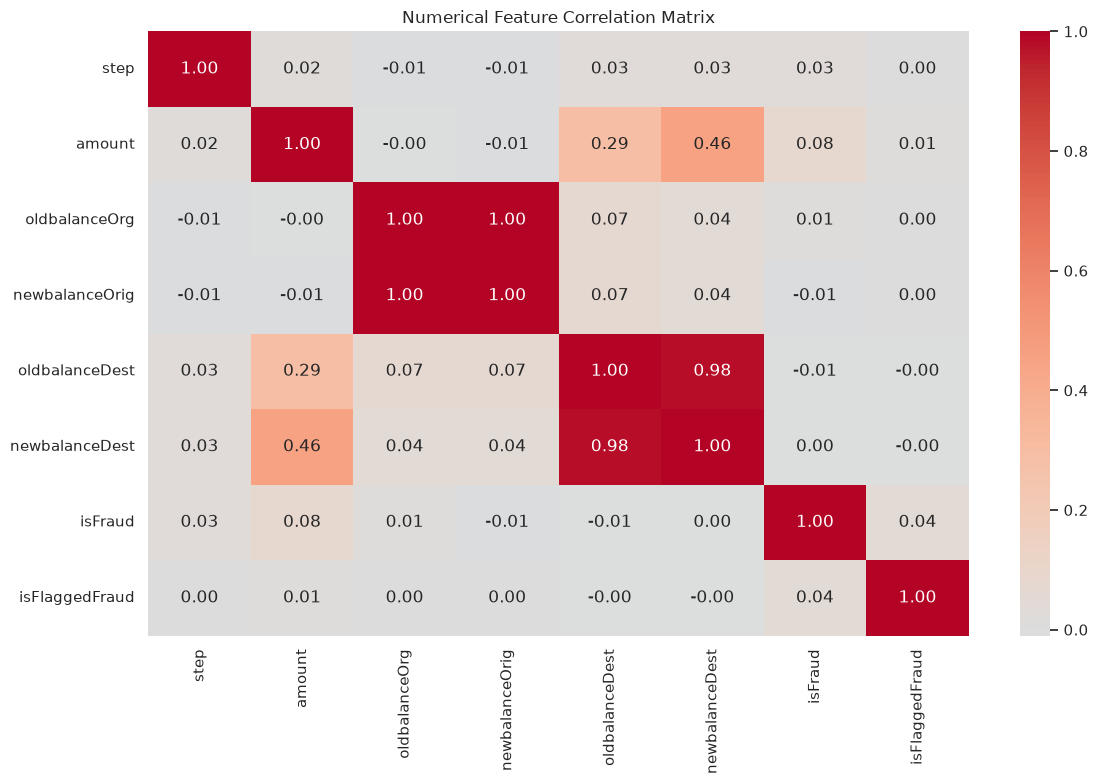

In [32]:
correlation = df.select_dtypes(
    include="number"
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Numerical Feature Correlation Matrix")
save_plot("eda_feature_correlation_matrix.png")

In [33]:
pd.crosstab(
    df["isFraud"],
    df["isFlaggedFraud"],
    rownames=["Actual Fraud"],
    colnames=["Flagged Fraud"],
    margins=True
)

Flagged Fraud,0,1,All
Actual Fraud,,,
0,6354407,0,6354407
1,8197,16,8213
All,6362604,16,6362620


In [34]:
print(
    classification_report(
        df["isFraud"],
        df["isFlaggedFraud"],
        target_names=["Legitimate", "Fraudulent"],
        digits=6,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Legitimate   0.998712  1.000000  0.999355   6354407
  Fraudulent   1.000000  0.001948  0.003889      8213

    accuracy                       0.998712   6362620
   macro avg   0.999356  0.500974  0.501622   6362620
weighted avg   0.998713  0.998712  0.998070   6362620



## Key Findings

### Data Quality
- The dataset contains 6,362,620 transactions and 11 variables.
- There are no missing values, duplicate rows, or negative transaction amounts or account balances.
- There are 16 zero-value transactions, while zero balances are common across account balance variables.
- No major data cleaning is required, although zero-value transactions and potential simulation artifacts should be investigated.

### Class Imbalance
- There are 6,354,407 legitimate transactions (99.8709%) and 8,213 fraudulent transactions (0.1291%).
- The dataset exhibits extreme class imbalance, with approximately 774 legitimate transactions for every fraudulent transaction.
- A model that predicts every transaction as legitimate would achieve approximately 99.87% accuracy without detecting any fraud.
- Precision, recall, F1-score, and PR-AUC should be prioritized over accuracy during model evaluation.

### Transaction Type Patterns
- CASH_OUT and PAYMENT are the most frequent transaction types.
- Fraud occurs exclusively in TRANSFER and CASH_OUT transactions.
- TRANSFER has the highest fraud rate at 0.7688%, followed by CASH_OUT at 0.1840%.
- CASH_OUT accounts for 4,116 fraudulent transactions, while TRANSFER accounts for 4,097.
- Transaction type is a potentially important predictive feature, although these patterns may reflect the design of the PaySim simulator rather than real-world fraud behavior.

### Transaction Amount Patterns
- Transaction amounts are heavily right-skewed, suggesting that a logarithmic transformation may be beneficial.
- Fraudulent transactions have an average amount of approximately 1,467,967 compared to 178,197 for legitimate transactions.
- The median fraudulent transaction amount is 441,423, compared to 74,685 for legitimate transactions.
- Fraudulent transactions account for approximately 12.06 billion in transaction value, representing 1.0535% of total transaction volume by value despite accounting for only 0.1291% of transactions.
- Transaction amount is a promising predictive feature, although large transaction amounts do not necessarily indicate fraud.
- Fraudulent transaction value should be incorporated into model evaluation alongside traditional classification metrics.

### Temporal Patterns
- The dataset covers 743 simulation hours, representing approximately 31 days of transaction activity.
- Transaction volume exhibits recurring peaks and periods of low activity.
- Overall transaction volume decreases substantially after approximately simulation hour 400, while fraudulent transaction counts remain relatively consistent.
- Some simulation hours exhibit fraud rates of 100%, corresponding to periods with very low overall transaction activity.
- These patterns suggest potential temporal distribution shifts and simulation artifacts.
- Chronological train, validation, and test splits should be used to evaluate model performance under changing transaction patterns and prevent temporal leakage.

### Account-Level Behavior
- The dataset contains 6,353,307 unique sender accounts and 2,722,362 unique recipient accounts.
- Sender accounts average approximately 1.001 transactions, with a maximum of 3 transactions per sender.
- Recipient accounts average approximately 2.337 transactions, with a maximum of 113 transactions per recipient.
- Sender-level historical features may have limited predictive value because nearly all sender accounts appear only once.
- Recipient-level historical features may be more useful due to greater recurring activity, although the median recipient still appears only once.
- All fraudulent transactions involve customer recipient accounts, while no fraudulent transactions involve merchant recipient accounts.
- Account identifiers should primarily be used to construct behavioral features rather than directly as categorical predictors.

### Potential Data Leakage
- Fraudulent and legitimate transactions exhibit substantial differences in their account balance distributions.
- However, PaySim's simulation process may introduce target leakage through account balance variables because detected fraudulent transactions can be canceled.
- The following variables will be excluded from the primary leakage-controlled model:
  - oldbalanceOrg
  - newbalanceOrig
  - oldbalanceDest
  - newbalanceDest
  - isFlaggedFraud
- Historical and rolling features must be calculated using only transactions observed before the transaction being scored.
- Transactions within the same simulation hour should be handled conservatively because their precise chronological ordering is not established.

### Existing Fraud Detection Limitations
- The existing rule-based fraud detection mechanism correctly identifies only 16 of the 8,213 fraudulent transactions.
- It produces zero false positives but misses 8,197 fraudulent transactions.
- The existing mechanism achieves:
  - Fraud Precision: 100.00%
  - Fraud Recall: 0.1948%
  - Fraud F1-Score: 0.003889
  - Accuracy: 99.8712%
- Despite its high precision and accuracy, the existing mechanism fails to detect nearly all fraudulent transactions.
- This demonstrates the need for a more effective machine learning-based fraud detection system.
- The existing mechanism will serve as a rule-based benchmark for evaluating future models.

### Implications for Feature Engineering and Modeling
- Prioritize transaction amount, transaction type, temporal features, and historical recipient behavior.
- Explore logarithmic transformations of transaction amounts to address skewness.
- Investigate historical transaction counts, cumulative transaction amounts, rolling averages, and recipient transaction velocity.
- Evaluate temporal features carefully to distinguish meaningful behavioral patterns from simulation-specific artifacts.
- Use chronological data splitting to simulate real-world fraud detection conditions.
- Investigate class weighting and cost-sensitive learning to address extreme class imbalance.
- Establish rule-based and logistic regression baselines before evaluating more advanced models such as XGBoost and LightGBM.
- Evaluate models using PR-AUC, precision, recall, F1-score, and fraudulent transaction value captured.
- Optimize classification thresholds based on the trade-off between missed fraud and false-positive investigation costs.
- Acknowledge that PaySim is a synthetic dataset and that model performance may not directly generalize to real-world financial transactions.

### Visualization Artifacts
- Exported seven selected EDA figures to `reports/figures/`, covering class imbalance, fraud rates by transaction type, transaction amount distributions by fraud status, temporal transaction volume and fraud patterns, and numerical feature correlations.
- Retained all original visualizations within the notebook.

## Conclusion

The exploratory data analysis reveals that fraud detection within the PaySim dataset is characterized by extreme class imbalance, distinct transaction type patterns, substantial differences in transaction amounts, and temporal distribution shifts.

The existing rule-based detection mechanism demonstrates extremely low fraud recall, providing a clear opportunity for machine learning-based improvement. However, potential data leakage, limited sender transaction history, and simulation-specific artifacts must be carefully addressed.

The next phase will focus on developing a leakage-controlled feature engineering pipeline that captures transaction characteristics, historical recipient behavior, and temporal patterns while maintaining realistic prediction conditions.